# Exploratory analysis using python

A guide for internal users to connect to Ember's data and visualise using python.

## Setup

This needs to be run once per session if using Colab. Not needed on a local environment


In [1]:
try:
  import google.colab
  IN_COLAB = True
except ImportError:
  IN_COLAB = False

if IN_COLAB:
  print("Running in Google Colab")
else:
  print("Running in a local environment")

Running in Google Colab


In [2]:
if IN_COLAB:
    !pip install google-cloud-storage
    !pip install google-cloud-bigquery
    from google.colab import auth
    auth.authenticate_user()

## Imports

If something fails here, add it to the `pip install` above

In [4]:
import pandas as pd
import seaborn as sns
from google.cloud import bigquery
from google.cloud import storage
import matplotlib as mpl
import matplotlib.pyplot as plt

### Set some styles

In [5]:
mpl.style.use('fivethirtyeight')
mpl.rcParams['font.size'] = 10       # Reduce font size
# Customize the background color
mpl.rcParams['axes.facecolor'] = '#f0f0f0'  # Almost white
mpl.rcParams['figure.facecolor'] = '#f0f0f0'  # Almost white

## Connect to db

In [6]:
# Create a Client:
project_id = 'emb-prod-376511'
dataset = 'generation'
location = 'EU'
table =  'analysis_generation_hourly_lower'

## Fetch some data

You can either add query conditions in the SQL query, or just fetch loads of data and then query it within python. If the table is very large (hourly tables are), it is better to restriction in the SQL if you're only interested in a particular subset.

In [10]:
use_cache=False
CACHE_FILE = './data.parquet'

In [11]:
if (not IN_COLAB) & use_cache:
    df_raw = pd.read_parquet(CACHE_FILE)
else:
    client = bigquery.Client(project=project_id, location=location)

    # Define your SQL query
    query = f"""
        SELECT *,
        FROM `{project_id}.{dataset}.{table}`
        WHERE EXTRACT(YEAR FROM DATETIME_LOCAL) >= 2023
        ORDER BY COUNTRY_CODE, DATETIME_LOCAL
    """

    # Run the query and get the results
    df_raw = client.query(query).to_dataframe()
    # Rename columns to lower case
    df_raw.columns = [c.lower() for c in df_raw.columns]
    df_raw.to_parquet(CACHE_FILE)

In [12]:
df_raw.head()

,country_or_region,country_code,datetime_local,datetime_utc,fuel,generation_mwh
0,AUT,AUT,2023-01-01,2022-12-31 23:00:00,Fossil,149.70000
1,AUT,AUT,2023-01-01,2022-12-31 23:00:00,Hydro,2449.34318
2,AUT,AUT,2023-01-01,2022-12-31 23:00:00,Pumped hydro storage,-1515.40000
3,AUT,AUT,2023-01-01,2022-12-31 23:00:00,Bioenergy,240.00000
4,AUT,AUT,2023-01-01,2022-12-31 23:00:00,Total generation,2301.71318


In [13]:
df_raw.dtypes


,0
country_or_region,object
country_code,object
datetime_local,datetime64[us]
datetime_utc,datetime64[us]
fuel,object
generation_mwh,float64


In [14]:
# Convert datetime columns to pandas datetime format
df_hourly = df_raw
df_hourly['datetime_local'] = pd.to_datetime(df_hourly['datetime_local'])
df_hourly['datetime_utc'] = pd.to_datetime(df_hourly['datetime_utc'])

This is the "long" format data, with containing both individual fuels (wind, solar), but also aggregates, "Wind and solar". For most analysis it is usually easier to have a "wide" version. Pivot is flexible.

In [15]:
df_l = df_hourly
df_w = df_l.pivot(index=[ 'country_code','datetime_utc', 'datetime_local'],
                  columns='fuel',
                  values='generation_mwh')\
           .reset_index()

In [16]:
df_w.columns = [c.lower().replace(' ', '_') for c in df_w.columns]


In [17]:
df_w


,country_code,datetime_utc,datetime_local,battery_storage,bioenergy,clean,coal,demand,fossil,gas,...,offshore_wind,onshore_wind,other_fossil,other_renewables,pumped_hydro_storage,renewables,solar,total_generation,wind,wind_and_solar
0,AUT,2022-12-31 23:00:00,2023-01-01 00:00:00,NaN,240.00000,3667.413180,0.0,5374.235680,149.700,27.700,...,NaN,978.00000,122.0,0.07,-1515.4,3667.413180,0.000000,2301.713180,978.00000,978.000000
1,AUT,2023-01-01 00:00:00,2023-01-01 01:00:00,NaN,240.00000,3530.767291,0.0,5158.764791,150.200,28.200,...,NaN,921.00000,122.0,0.07,-1586.2,3530.767291,0.000000,2094.767291,921.00000,921.000000
2,AUT,2023-01-01 01:00:00,2023-01-01 02:00:00,NaN,240.00000,3515.681244,0.0,4996.816244,150.200,28.200,...,NaN,956.00000,122.0,0.07,-1696.7,3515.681244,0.000000,1969.181244,956.00000,956.000000
3,AUT,2023-01-01 02:00:00,2023-01-01 03:00:00,NaN,240.00000,3407.858344,0.0,4862.835844,157.800,35.800,...,NaN,855.00000,122.0,0.07,-1723.2,3407.858344,0.000000,1842.458344,855.00000,855.000000
4,AUT,2023-01-01 03:00:00,2023-01-01 04:00:00,NaN,242.00000,3308.283561,0.0,4947.656061,173.500,51.500,...,NaN,547.00000,122.0,0.07,-1665.5,3308.283561,0.000000,1816.283561,547.00000,547.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
678071,SWE,2025-11-13 05:00:00,2025-11-13 06:00:00,NaN,615.39000,19995.070187,NaN,14763.166886,0.400,0.400,...,NaN,7753.86425,NaN,NaN,NaN,14185.070187,2.201687,19995.470187,7753.86425,7756.065937
678072,SWE,2025-11-13 06:00:00,2025-11-13 07:00:00,NaN,653.09475,20674.057091,NaN,15329.143019,0.700,0.700,...,NaN,7611.88275,NaN,NaN,NaN,14865.057091,3.309591,20674.757091,7611.88275,7615.192341
678073,SWE,2025-11-13 07:00:00,2025-11-13 08:00:00,NaN,676.69150,21397.006897,NaN,15740.631636,1.800,1.800,...,NaN,7640.92475,NaN,NaN,NaN,15590.006897,19.412397,21398.806897,7640.92475,7660.337147
678074,SWE,2025-11-13 08:00:00,2025-11-13 09:00:00,NaN,706.12925,21888.624619,NaN,16224.822355,1.700,1.700,...,NaN,7751.58575,NaN,NaN,NaN,16085.624619,58.783119,21890.324619,7751.58575,7810.368869


In [18]:
# add some further date/time columns for ease of analysis
df_w['year'] = df_w.datetime_local.dt.year
df_w['month'] = df_w.datetime_local.dt.month
df_w['dayofmonth'] = df_w.datetime_local.dt.day
df_w['dayofyear'] = df_w['datetime_local'].dt.dayofyear
df_w['hour'] = df_w.datetime_local.dt.hour

df_w['day_type'] = df_w['datetime_local'].dt.dayofweek.apply(
    lambda x: 'weekend' if x >= 5 else 'weekday'
)

season_map = {
    1: 'winter', 2: 'winter',
    3: 'spring', 4: 'spring', 5: 'spring',
    6: 'summer', 7: 'summer', 8: 'summer',
    9: 'autumn', 10: 'autumn', 11: 'autumn',
    12: 'winter'
}

# Use the .map() method to create the 'season' column
df_w['season'] = df_w['month'].map(season_map)


What if we're interested in public holidays?

In [19]:
# save us some typing througout the rest of the notebook
# df_l = long, df_w = wide
df_w

,country_code,datetime_utc,datetime_local,battery_storage,bioenergy,clean,coal,demand,fossil,gas,...,total_generation,wind,wind_and_solar,year,month,dayofmonth,dayofyear,hour,day_type,season
0,AUT,2022-12-31 23:00:00,2023-01-01 00:00:00,NaN,240.00000,3667.413180,0.0,5374.235680,149.700,27.700,...,2301.713180,978.00000,978.000000,2023,1,1,1,0,weekend,winter
1,AUT,2023-01-01 00:00:00,2023-01-01 01:00:00,NaN,240.00000,3530.767291,0.0,5158.764791,150.200,28.200,...,2094.767291,921.00000,921.000000,2023,1,1,1,1,weekend,winter
2,AUT,2023-01-01 01:00:00,2023-01-01 02:00:00,NaN,240.00000,3515.681244,0.0,4996.816244,150.200,28.200,...,1969.181244,956.00000,956.000000,2023,1,1,1,2,weekend,winter
3,AUT,2023-01-01 02:00:00,2023-01-01 03:00:00,NaN,240.00000,3407.858344,0.0,4862.835844,157.800,35.800,...,1842.458344,855.00000,855.000000,2023,1,1,1,3,weekend,winter
4,AUT,2023-01-01 03:00:00,2023-01-01 04:00:00,NaN,242.00000,3308.283561,0.0,4947.656061,173.500,51.500,...,1816.283561,547.00000,547.000000,2023,1,1,1,4,weekend,winter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
678071,SWE,2025-11-13 05:00:00,2025-11-13 06:00:00,NaN,615.39000,19995.070187,NaN,14763.166886,0.400,0.400,...,19995.470187,7753.86425,7756.065937,2025,11,13,317,6,weekday,autumn
678072,SWE,2025-11-13 06:00:00,2025-11-13 07:00:00,NaN,653.09475,20674.057091,NaN,15329.143019,0.700,0.700,...,20674.757091,7611.88275,7615.192341,2025,11,13,317,7,weekday,autumn
678073,SWE,2025-11-13 07:00:00,2025-11-13 08:00:00,NaN,676.69150,21397.006897,NaN,15740.631636,1.800,1.800,...,21398.806897,7640.92475,7660.337147,2025,11,13,317,8,weekday,autumn
678074,SWE,2025-11-13 08:00:00,2025-11-13 09:00:00,NaN,706.12925,21888.624619,NaN,16224.822355,1.700,1.700,...,21890.324619,7751.58575,7810.368869,2025,11,13,317,9,weekday,autumn


In [20]:
df_w.columns

Index(['country_code', 'datetime_utc', 'datetime_local', 'battery_storage',
       'bioenergy', 'clean', 'coal', 'demand', 'fossil', 'gas', 'hard_coal',
       'hydro', 'hydro,_bioenergy_and_other_renewables', 'lignite',
       'net_import', 'nuclear', 'offshore_wind', 'onshore_wind',
       'other_fossil', 'other_renewables', 'pumped_hydro_storage',
       'renewables', 'solar', 'total_generation', 'wind', 'wind_and_solar',
       'year', 'month', 'dayofmonth', 'dayofyear', 'hour', 'day_type',
       'season'],
      dtype='object')

## Check data quality!

When working with hourly data, which do not flow directly into our mothly totals, it is worth doing some checks. Here we work out the % of missing hours by month.

**Don't use aggregated hourly data externally without checking with the Data Team!**




In [21]:
df_w[df_w['total_generation'].isna()]

,country_code,datetime_utc,datetime_local,battery_storage,bioenergy,clean,coal,demand,fossil,gas,...,total_generation,wind,wind_and_solar,year,month,dayofmonth,dayofyear,hour,day_type,season
149727,DEU,2025-11-13 09:00:00,2025-11-13 10:00:00,NaN,NaN,NaN,NaN,-5837.620413,NaN,NaN,...,NaN,NaN,NaN,2025,11,13,317,10,weekday,autumn
676999,SWE,2025-09-29 13:00:00,2025-09-29 15:00:00,NaN,NaN,NaN,NaN,-3795.150000,NaN,NaN,...,NaN,NaN,NaN,2025,9,29,272,15,weekday,autumn
677000,SWE,2025-09-29 14:00:00,2025-09-29 16:00:00,NaN,NaN,NaN,NaN,-4068.190000,NaN,NaN,...,NaN,NaN,NaN,2025,9,29,272,16,weekday,autumn
677001,SWE,2025-09-29 15:00:00,2025-09-29 17:00:00,NaN,NaN,NaN,NaN,-3397.230000,NaN,NaN,...,NaN,NaN,NaN,2025,9,29,272,17,weekday,autumn
677002,SWE,2025-09-29 16:00:00,2025-09-29 18:00:00,NaN,NaN,NaN,NaN,-3135.050000,NaN,NaN,...,NaN,NaN,NaN,2025,9,29,272,18,weekday,autumn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
677773,SWE,2025-10-31 19:00:00,2025-10-31 20:00:00,NaN,NaN,NaN,NaN,-3913.287380,NaN,NaN,...,NaN,NaN,NaN,2025,10,31,304,20,weekday,autumn
677774,SWE,2025-10-31 20:00:00,2025-10-31 21:00:00,NaN,NaN,NaN,NaN,-4322.391528,NaN,NaN,...,NaN,NaN,NaN,2025,10,31,304,21,weekday,autumn
677775,SWE,2025-10-31 21:00:00,2025-10-31 22:00:00,NaN,NaN,NaN,NaN,-4610.134021,NaN,NaN,...,NaN,NaN,NaN,2025,10,31,304,22,weekday,autumn
677776,SWE,2025-10-31 22:00:00,2025-10-31 23:00:00,NaN,NaN,NaN,NaN,-4760.564446,NaN,NaN,...,NaN,NaN,NaN,2025,10,31,304,23,weekday,autumn


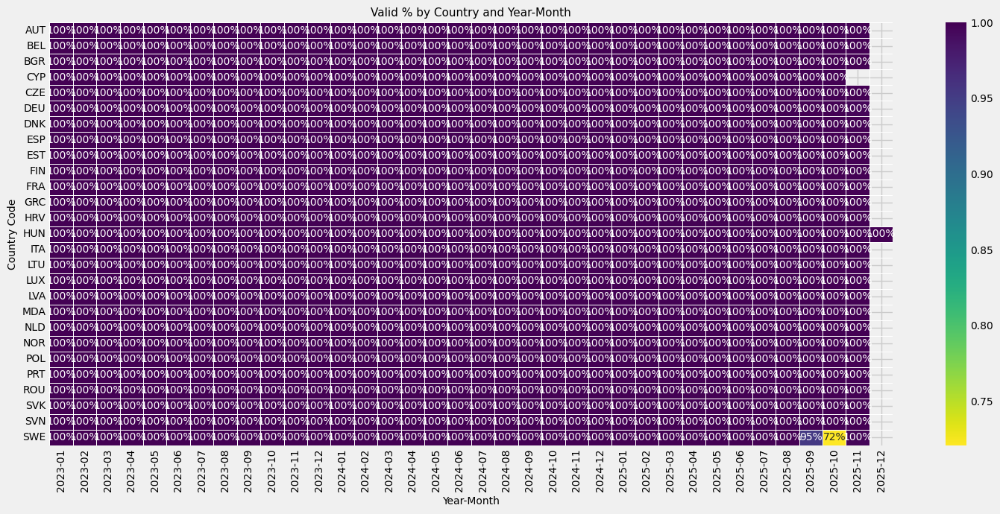

In [22]:
# Calculate valid hours per country, year, and month
valid_hours_per_country_month = df_w.groupby(['country_code', 'year', 'month'])['total_generation'].count()
total_hours_per_country_month = df_w.groupby(['country_code', 'year', 'month']).size()
valid_proportion = (valid_hours_per_country_month / total_hours_per_country_month)

# Convert the series to a DataFrame
valid_df = valid_proportion.to_frame(name='valid_proportion').reset_index()

# Create a year-month column for the heatmap
valid_df['year_month'] = valid_df['year'].astype(str) + '-' + valid_df['month'].astype(str).str.zfill(2)

# Pivot the data for the heatmap
heatmap_data = valid_df.pivot(index='country_code', columns='year_month', values='valid_proportion')

plt.figure(figsize=(15, 7))

sns.heatmap(
    heatmap_data,
    annot=True,          # Show the percentage values in the cells
    fmt='.0%',           # Format annotations as percentages with one decimal place
    cmap='viridis_r',    # Use a color map (reversed viridis is good for showing "bad" as light)
    linewidths=.5,       # Add lines between cells
#    cbar_kws={'label': 'Proportion of Missing Data'} # Label for the color bar
)

plt.title('Valid % by Country and Year-Month', fontsize=11)
plt.xlabel('Year-Month', fontsize=10)
plt.ylabel('Country Code', fontsize=10)
plt.xticks(rotation=90) # Rotate year-month labels for better visibility
plt.yticks(rotation=0)

plt.tight_layout() # Adjust layout to prevent labels overlapping

plt.savefig(f'valid_data_by_country_month.png', dpi=300, bbox_inches='tight')

### Cumulative Generation

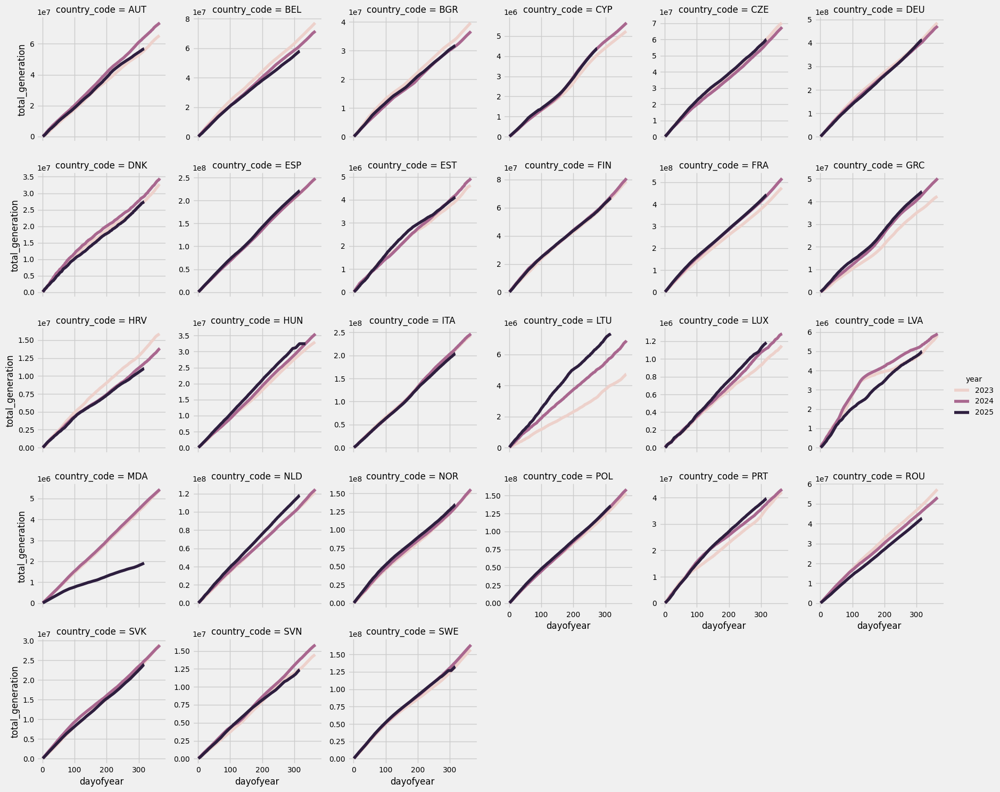

In [30]:
column = 'total_generation'
data = df_w.groupby(['country_code', 'year', 'dayofyear'], as_index=False)\
           .agg({column: 'sum'})\
           .sort_values(['country_code', 'year', 'dayofyear'])

# Group by 'year' and calculate the cumulative sum of 'value' for each group
data[column] = data.groupby(['country_code', 'year']).cumsum()[column]

sns.relplot(data=data,
            x='dayofyear',
            y=column,
            hue='year',
            col='country_code',
            col_wrap=6,
            height=3,
            errorbar=None,
            kind='line',
            facet_kws={'sharey': False}
            )
plt.savefig(f'{column}_cumulative_by_country_dayofyear.png', dpi=300, bbox_inches='tight')

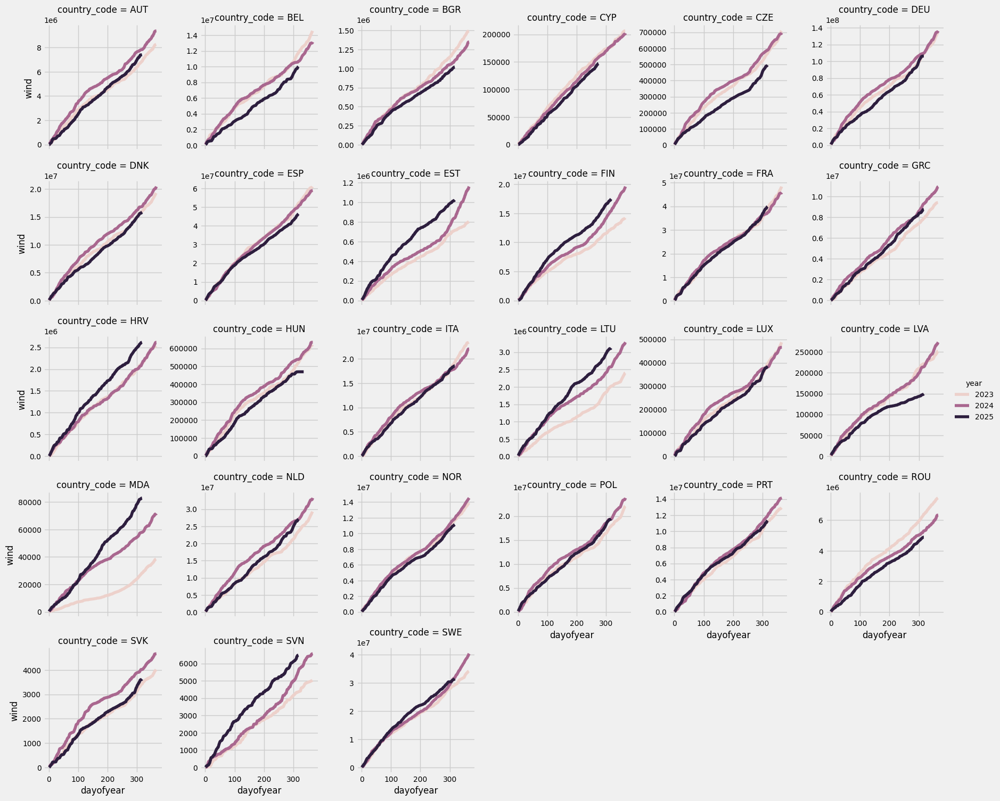

In [29]:
column = 'wind'
data = df_w.groupby(['country_code', 'year', 'dayofyear'], as_index=False)\
           .agg({column: 'sum'})\
           .sort_values(['country_code', 'year', 'dayofyear'])

# Group by 'year' and calculate the cumulative sum of 'value' for each group
data[column] = data.groupby(['country_code', 'year']).cumsum()[column]

sns.relplot(data=data,
            x='dayofyear',
            y=column,
            hue='year',
            col='country_code',
            col_wrap=6,
            height=3,
            errorbar=None,
            kind='line',
            facet_kws={'sharey': False}
            )
plt.savefig(f'{column}_cumulative_by_country_dayofyear.png', dpi=300, bbox_inches='tight')


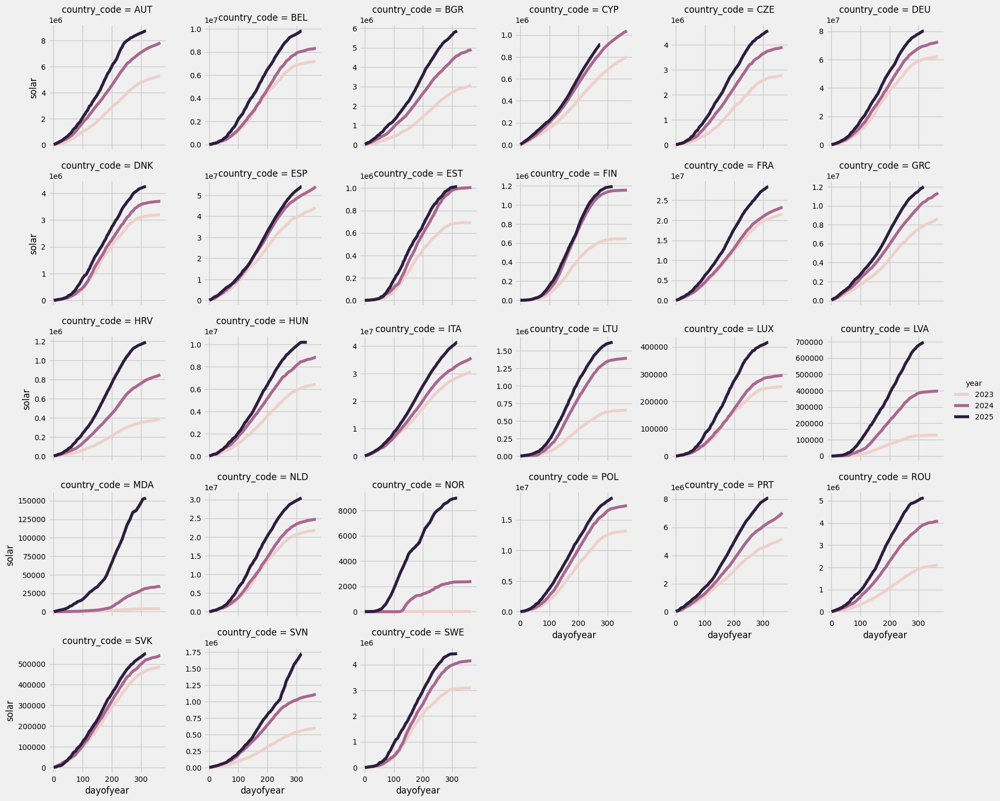

In [25]:
column = 'solar'
data = df_w.groupby(['country_code', 'year', 'dayofyear'], as_index=False)\
           .agg({column: 'sum'})\
           .sort_values(['country_code', 'year', 'dayofyear'])

# Group by 'year' and calculate the cumulative sum of 'value' for each group
data[column] = data.groupby(['country_code', 'year']).cumsum()[column]

sns.relplot(data=data,
            x='dayofyear',
            y=column,
            hue='year',
            col='country_code',
            col_wrap=6,
            height=3,
            errorbar=None,
            kind='line',
            facet_kws={'sharey': False}
            )


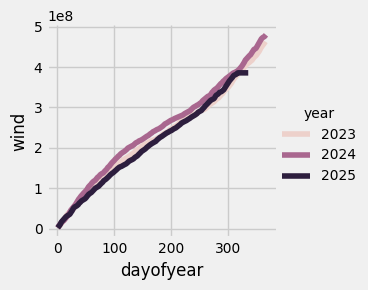

In [26]:
column = 'wind'
data = df_w.groupby(['year', 'dayofyear'], as_index=False)\
           .agg({column: 'sum'})\
           .sort_values(['year', 'dayofyear'])

# Group by 'year' and calculate the cumulative sum of 'value' for each group
data[column] = data.groupby([ 'year']).cumsum()[column]

sns.relplot(data=data,
            x='dayofyear',
            y=column,
            hue='year',
            #col='country_code',
            #col_wrap=6,
            height=3,
            errorbar=None,
            kind='line',
            facet_kws={'sharey': False}
            )

Go wild. Seaborn is a quick and flexible way of plotting data in all manner of ways. Just change the x and y values, hue, col etc. Ask Gemini direct from colab.


### Generation by hour

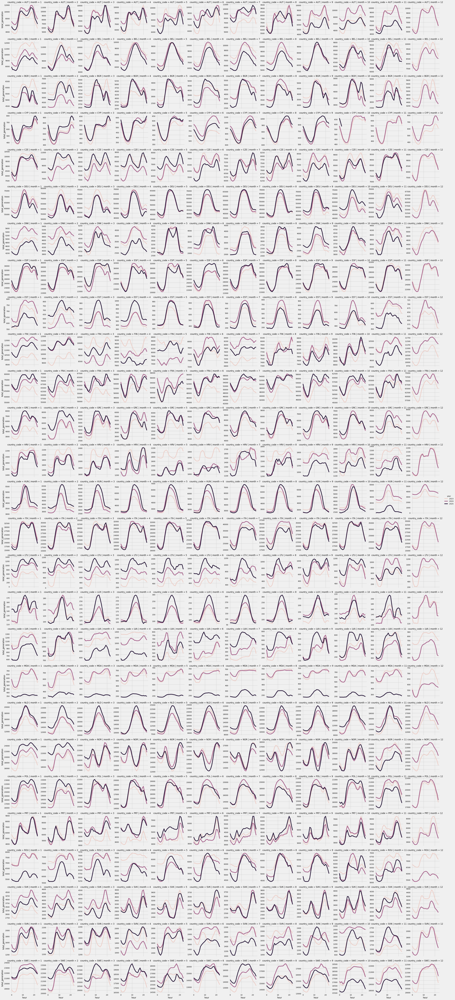

In [27]:
column = 'total_generation'
data = df_w
sns.relplot(data=data,
            x='hour',
            y=column,
            hue='year',
            col='month',
            row='country_code',
            #col_wrap=6,
            height=3,
            errorbar=None,
            kind='line',
            facet_kws={'sharey': False}
            )
plt.savefig('generation_by_hour.png', dpi=300, bbox_inches='tight')

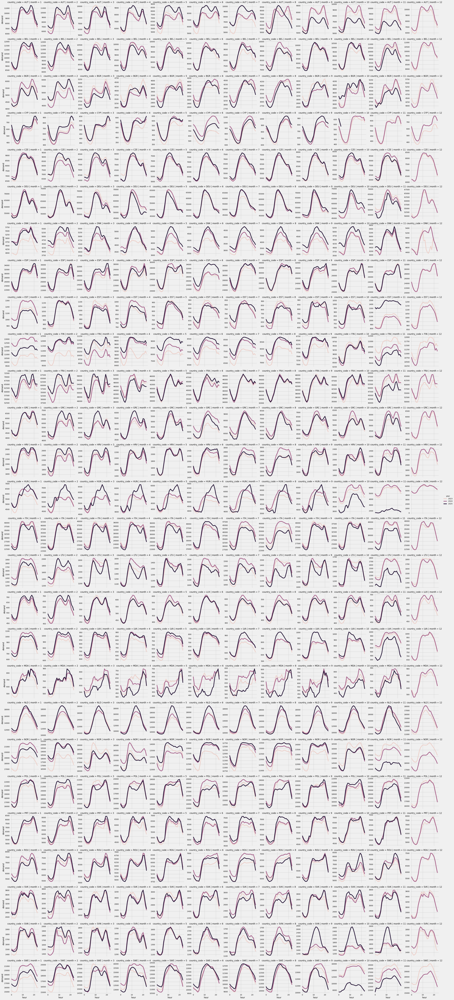

In [28]:
column = 'demand'
data = df_w
sns.relplot(data=data,
            x='hour',
            y=column,
            hue='year',
            col='month',
            row='country_code',
            #col_wrap=6,
            height=3,
            errorbar=None,
            kind='line',
            facet_kws={'sharey': False}
            )
plt.savefig(f'{column}_by_hour.png', dpi=300, bbox_inches='tight')